# Fase Correlazioni
Obiettivo: misurare con i numeri quanto i prezzi del carrello si muovono insieme
alle materie prime e al rischio geopolitico, e con quale ritardo.

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROCESSED = Path("../data_market/processed")
dataset = pd.read_csv(PROCESSED / "dataset_mensile.csv", index_col="data", parse_dates=True)

PRODOTTI = ["pane", "pasta", "olio_girasole", "caffe", "zucchero", "latte", "carburanti"]
CONFRONTI = {
    "pane": "grano",
    "pasta": "grano",
    "olio_girasole": "girasole_mondo",
    "caffe": "caffe_robusta",  #la robusta è la più usata nelle miscele italiane
    "zucchero": "zucchero_mondo",
    "latte": "fao_latticini",
    "carburanti": "brent",
}

def in_euro(serie):
    """Converte un prezzo in dollari in euro."""
    return serie / dataset["eur_usd"]

In [39]:
# Due serie che non c'entrano niente tra loro
a = dataset["latte"]
b = dataset["gpr_usa"]

print("Correlazione sui livelli:    ", round(a.corr(b), 2))
print("Correlazione su variazioni 1m:", round(a.pct_change(fill_method=None).corr(b.pct_change(fill_method=None)), 2))

Correlazione sui livelli:     0.53
Correlazione su variazioni 1m: -0.05


### La trappola dei livelli (correlazione spuria)
Latte italiano e GPR degli USA non hanno alcun legame, ma la correlazione sui livelli
è 0,53 perché nel periodo sono saliti entrambi. Sulle variazioni mensili scende a −0,05.
Per questo tutte le correlazioni di questa fase sono calcolate sulle **variazioni**.

In [40]:
def var12(serie):
    """Variazione % rispetto allo stesso mese dell'anno prima."""
    return serie.pct_change(12, fill_method=None) * 100

righe = []
for prodotto, materia in CONFRONTI.items():
    v_prodotto = var12(dataset[prodotto])
    v_materia = var12(in_euro(dataset[materia]))
    righe.append({
        "prodotto": prodotto,
        "materia_prima": materia,
        "corr_materia_prima": v_prodotto.corr(v_materia),
        "corr_gpr": v_prodotto.corr(dataset["gpr"]),
    })

tabella = pd.DataFrame(righe).set_index("prodotto").round(2)
tabella

,materia_prima,corr_materia_prima,corr_gpr
prodotto,,,
pane,grano,0.11,0.14
pasta,grano,0.43,0.07
olio_girasole,girasole_mondo,0.40,0.08
caffe,caffe_robusta,0.09,0.44
zucchero,zucchero_mondo,0.25,-0.05
latte,fao_latticini,0.13,0.05
carburanti,brent,0.87,0.28


### Correlazioni nello stesso mese (variazioni su 12 mesi)

| Prodotto | Materia prima | Corr. con materia prima | Corr. con GPR |
|---|---|---|---|
| Carburanti | Brent | **0,87** | 0,28 |
| Pasta | Grano | 0,43 | 0,07 |
| Olio di girasole | Girasole mondiale | 0,40 | 0,08 |
| Zucchero | Zucchero mondiale | 0,25 | −0,05 |
| Latte | Indice FAO latticini | 0,13 | 0,05 |
| Pane | Grano | 0,11 | 0,14 |
| Caffè | Caffè Robusta | 0,09 | **0,44** |

**Tre gruppi.**
- **Legame forte e immediato**: i carburanti seguono il Brent nello stesso mese.
- **Legame medio**: pasta, olio di girasole e zucchero si muovono con la materia prima,
  ma non perfettamente.
- **Legame quasi nullo**: pane, latte e caffè. Nel Grafico 3, però, il caffè italiano
  seguiva chiaramente la Robusta.

**Perché alcuni valori sono bassi: il ritardo.** Questa tabella confronta i prezzi
nello stesso mese. Se un prodotto segue la materia prima con mesi di ritardo
(come caffè e zucchero nel Grafico 3), il legame non si vede. Il ritardo viene
misurato nel passo successivo.

**Caffè e GPR: correlazione senza causalità.** La correlazione del caffè con il GPR (0,44)
è più alta di quella con la Robusta. Ma il caffè è salito nel 2025 per il prezzo
mondiale della materia prima (raccolti), mentre il GPR era alto per altri motivi
(guerra dei 12 giorni, tensioni con l'Iran). Due fenomeni contemporanei, senza
legame causale.

**Ipotesi della Fase 3** ("i prezzi seguono più le materie prime che il GPR"):
**confermata in parte**. Vale per carburanti, pasta, olio di girasole e zucchero,
non per pane, latte e caffè. Da rivedere dopo l'analisi del ritardo.

In [41]:
LAG_MAX = 12
risultati = {}

for prodotto, materia in CONFRONTI.items():
    v_prodotto = var12(dataset[prodotto])
    v_materia = var12(in_euro(dataset[materia]))
    risultati[prodotto] = [v_prodotto.corr(v_materia.shift(lag)) for lag in range(LAG_MAX + 1)]

lag_tab = pd.DataFrame(risultati, index=range(LAG_MAX + 1))
lag_tab.index.name = "ritardo (mesi)"
lag_tab.round(2)

,pane,pasta,olio_girasole,caffe,zucchero,latte,carburanti
ritardo (mesi),,,,,,,
0,0.11,0.43,0.40,0.09,0.25,0.13,0.87
1,0.23,0.52,0.50,0.18,0.24,0.25,0.89
2,0.33,0.61,0.55,0.28,0.23,0.37,0.82
3,0.42,0.68,0.59,0.38,0.24,0.48,0.72
4,0.51,0.74,0.62,0.48,0.24,0.57,0.65
5,0.58,0.78,0.64,0.56,0.24,0.64,0.59
6,0.64,0.81,0.65,0.64,0.25,0.69,0.51
7,0.69,0.82,0.66,0.71,0.26,0.72,0.43
8,0.72,0.81,0.66,0.77,0.26,0.73,0.34


### Il ritardo (lag) tra materie prime e prezzi italiani

Per ogni prodotto si calcola la correlazione tra la sua variazione su 12 mesi e quella
della materia prima **spostata indietro di 0, 1, 2… mesi**: con un ritardo di 3 mesi,
il prezzo italiano di giugno viene confrontato con la materia prima di marzo.
Il ritardo con la correlazione più alta indica dopo quanto tempo il prezzo italiano
"segue" la materia prima.

| Prodotto | Corr. nello stesso mese | Ritardo migliore | Corr. con il ritardo |
|---|---|---|---|
| Carburanti | 0,87 | circa 1 mese | 0,89 |
| Pasta | 0,43 | circa 7 mesi | 0,82 |
| Latte | 0,13 | circa 8 mesi | 0,73 |
| Olio di girasole | 0,40 | circa 7–8 mesi | 0,66 |
| Pane | 0,11 | circa 10 mesi | 0,75 |
| Caffè | 0,09 | circa 11 mesi | 0,84 |
| Zucchero | 0,25 | 12 mesi o più (da verificare) | 0,31 |

**Con il ritardo, quasi tutti i legami diventano forti.**
- **Carburanti**: si adeguano al Brent in circa un mese.
- **Pane e pasta**: il grano arriva al supermercato dopo 7–10 mesi
  (contratti a lungo termine e scorte di mulini e pastifici).
- **Caffè**: quasi un anno, perché i torrefattori comprano il caffè verde con anticipo.
  Spiega perché il caffè italiano è salito nel 2025, dopo la Robusta del 2024.

**Avvertenze.**
- **Zucchero**: la correlazione cresce ancora a 12 mesi, quindi il massimo potrebbe
  essere oltre. Calcolo ripetuto con un ritardo massimo di 18 mesi.
- **Il ritardo migliore è approssimativo**: le correlazioni cambiano poco tra mesi vicini
  (per la pasta 0,81–0,82 tra 6 e 9 mesi), quindi va letto come "intorno a".
- **Olio di girasole**: nel Grafico 3 la reazione iniziale sembrava di 1–2 mesi.
  La correlazione misura invece la somiglianza dell'intero movimento, salita e discesa;
  e il prezzo italiano scende molto più lentamente di quello mondiale ("razzo e piuma").
- Le variazioni su 12 mesi di mesi vicini si sovrappongono: questo tende a rendere
  le correlazioni un po' più alte di quanto siano.

### Un confronto equo con il GPR
Per verificare l'ipotesi della Fase Esplorativa in modo corretto, lo stesso calcolo del ritardo
viene applicato anche al GPR: ogni prodotto riceve lo stesso trattamento con le due
variabili (ritardo da 0 a 18 mesi).

In [42]:
LAG_MAX = 18
risultati_materia, risultati_gpr = {}, {}

for prodotto, materia in CONFRONTI.items():
    v_prodotto = var12(dataset[prodotto])
    v_materia = var12(in_euro(dataset[materia]))
    risultati_materia[prodotto] = [v_prodotto.corr(v_materia.shift(l)) for l in range(LAG_MAX + 1)]
    risultati_gpr[prodotto] = [v_prodotto.corr(dataset["gpr"].shift(l)) for l in range(LAG_MAX + 1)]

lag_materia = pd.DataFrame(risultati_materia, index=range(LAG_MAX + 1))
lag_gpr = pd.DataFrame(risultati_gpr, index=range(LAG_MAX + 1))

confronto = pd.DataFrame({
    "lag_materia": lag_materia.idxmax(),
    "corr_materia": lag_materia.max().round(2),
    "lag_gpr": lag_gpr.idxmax(),
    "corr_gpr": lag_gpr.max().round(2),
})
confronto

,lag_materia,corr_materia,lag_gpr,corr_gpr
pane,10,0.75,7,0.37
pasta,7,0.82,8,0.15
olio_girasole,8,0.66,3,0.23
caffe,11,0.84,9,0.51
zucchero,15,0.35,10,0.29
latte,8,0.73,9,0.38
carburanti,1,0.89,0,0.28


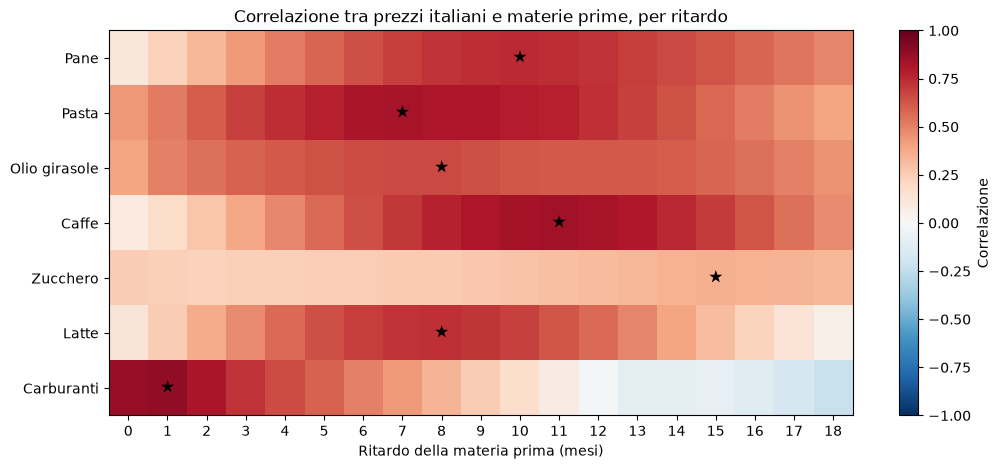

In [43]:
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(lag_materia.T, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")

ax.set_yticks(range(len(lag_materia.columns)))
ax.set_yticklabels([p.replace("_", " ").capitalize() for p in lag_materia.columns])
ax.set_xticks(range(LAG_MAX + 1))
ax.set_xlabel("Ritardo della materia prima (mesi)")
ax.set_title("Correlazione tra prezzi italiani e materie prime, per ritardo")

for i, prodotto in enumerate(lag_materia.columns):
    j = lag_materia[prodotto].idxmax()
    ax.text(j, i, "★", ha="center", va="center", color="black", fontsize=12)

fig.colorbar(im, ax=ax, label="Correlazione")
plt.show()

### Heatmap delle correlazioni per ritardo

Ogni riga è un prodotto, ogni colonna un ritardo della materia prima (in mesi);
il colore indica la correlazione (rosso = positiva, blu = negativa) e la ★ il ritardo migliore.

- **Carburanti**: legame forte solo nei primi mesi, poi svanisce.
  Reazione immediata e breve.
- **Pane, pasta, latte, caffè**: fascia rossa tra 6 e 12 mesi.
  Reazione lenta e prolungata: le materie prime arrivano al supermercato con mesi di ritardo.
- **Olio di girasole**: legame simile per molti mesi, segno di un adeguamento lento.
- **Zucchero**: legame debole per qualsiasi ritardo; il prezzo italiano segue poco
  il mercato mondiale.

**Conclusione:** i prezzi italiani seguono le materie prime, ma con tempi molto diversi:
un mese per l'energia, quasi un anno per alcuni alimentari.
Anche dando lo stesso ritardo al GPR, per tutti i prodotti la correlazione con la
materia prima resta più alta di quella con il rischio geopolitico globale.

In [44]:
GPR_PAESE = {
    "pane": "gpr_russia", "pasta": "gpr_russia", "olio_girasole": "gpr_ucraina",
    "carburanti": "gpr_russia",
}
righe = []
for prodotto, col_gpr in GPR_PAESE.items():
    v = var12(dataset[prodotto])
    globale = max(v.corr(dataset["gpr"].shift(l)) for l in range(LAG_MAX + 1))
    paese = max(v.corr(dataset[col_gpr].shift(l)) for l in range(LAG_MAX + 1))
    righe.append({"prodotto": prodotto, "gpr_paese": col_gpr,
                  "corr_gpr_globale": round(globale, 2), "corr_gpr_paese": round(paese, 2)})
pd.DataFrame(righe).set_index("prodotto")

,gpr_paese,corr_gpr_globale,corr_gpr_paese
prodotto,,,
pane,gpr_russia,0.37,0.70
pasta,gpr_russia,0.15,0.60
olio_girasole,gpr_ucraina,0.23,0.59
carburanti,gpr_russia,0.28,0.42


### Il GPR del paese giusto

| Prodotto | GPR globale | GPR del paese collegato |
|---|---|---|
| Pane | 0,37 | 0,70 (Russia) |
| Pasta | 0,15 | 0,60 (Russia) |
| Olio di girasole | 0,23 | 0,59 (Ucraina) |
| Carburanti | 0,28 | 0,42 (Russia) |

Per tutti e quattro i prodotti, il rischio geopolitico del paese produttore è più legato
ai prezzi del rischio globale. Per i carburanti è stato provato anche Israele (0,04):
il suo picco principale (Gaza 2023) ha pesato poco sul petrolio. La Russia spiega lo shock
energetico del 2022, ma non quello del 2026 legato all'Iran (non coperto dal GPR):
per questo la correlazione resta molto più bassa di quella con il Brent (0,89).
Attenzione: gli indici di Russia e Ucraina hanno in pratica un solo grande episodio (2022),
quindi queste correlazioni dipendono quasi tutte da un singolo evento.